# Customer Churn Prediction
Predicting which telecom customers will leave, and choosing a decision threshold by **business cost**, not by accuracy.

**Dataset:** IBM Telco Customer Churn (7,043 customers, 21 columns)
**Goal:** flag customers likely to churn so the company can offer retention support before they leave.

**Sections:** 1. Setup · 2. Data cleaning · 3. Exploratory analysis · 4. Preprocessing · 5. Models · 6. Cross-validation · 7. Threshold by business cost · 8. Final evaluation

## 1. Setup

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report
from xgboost import XGBClassifier

URL = 'https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv'
df = pd.read_csv(URL)
df.shape

(7043, 21)

## 2. Data cleaning
`isnull()` reports no missing values, but `TotalCharges` is stored as text. Converting it with `errors='coerce'` reveals 11 hidden blanks.

In [8]:
print(df.isnull().sum().sum(), df['TotalCharges'].dtype)

bad = pd.to_numeric(df['TotalCharges'], errors='coerce').isnull()
df.loc[bad, ['customerID', 'tenure', 'TotalCharges']]

0 object


,customerID,tenure,TotalCharges
488,4472-LVYGI,0,
753,3115-CZMZD,0,
936,5709-LVOEQ,0,
1082,4367-NUYAO,0,
1340,1371-DWPAZ,0,
3331,7644-OMVMY,0,
3826,3213-VVOLG,0,
4380,2520-SGTTA,0,
5218,2923-ARZLG,0,
6670,4075-WKNIU,0,


All 11 customers have `tenure = 0`: they joined this month and have not been billed yet, so the correct value is **0**, not the column mean.

In [10]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce').fillna(0)

# verify the result, not just the null count
print(df['TotalCharges'].dtype, (df['TotalCharges'] == 0).sum())

float64 11


## 3. Exploratory analysis
Churn is imbalanced (about 26.5% yes), so accuracy alone will be misleading.

In [12]:
df['Churn'].value_counts(normalize=True) * 100

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

Churn                  No        Yes
Contract                            
Month-to-month  57.290323  42.709677
One year        88.730482  11.269518
Two year        97.168142   2.831858
Contract
Month-to-month    66.398490
One year          65.048608
Two year          60.770413
Name: MonthlyCharges, dtype: float64


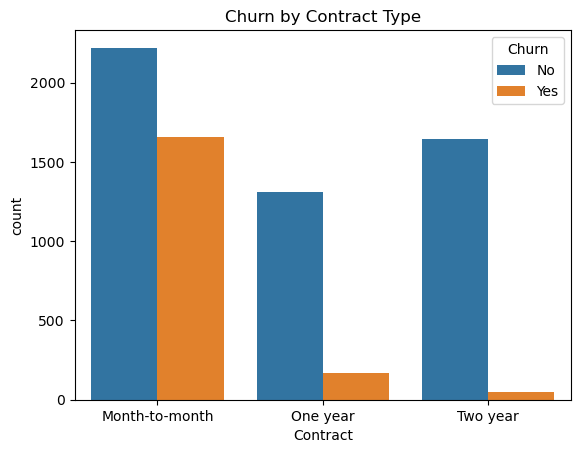

In [13]:
print(df.groupby('Contract')['Churn'].value_counts(normalize=True).unstack() * 100)
print(df.groupby('Contract')['MonthlyCharges'].mean())

sns.countplot(data=df, x='Contract', hue='Churn')
plt.title('Churn by Contract Type')
plt.show()

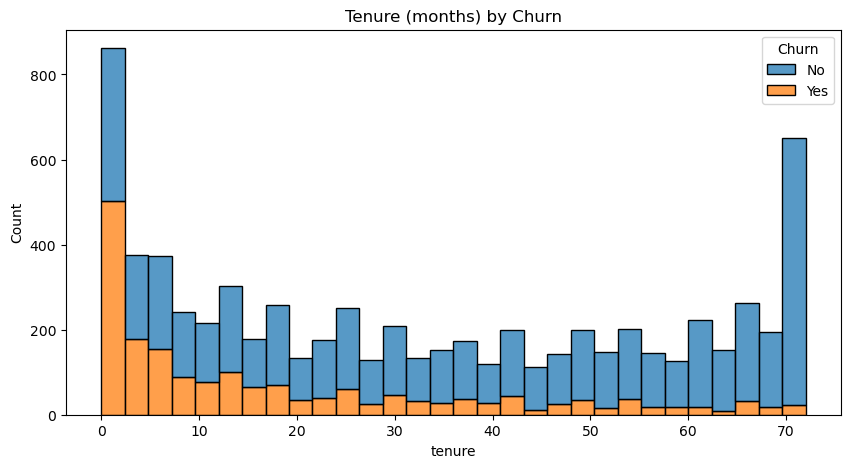

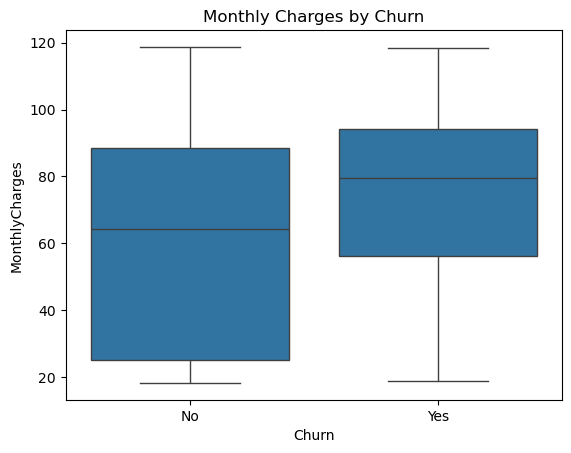

In [14]:
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x='tenure', hue='Churn', bins=30, multiple='stack')
plt.title('Tenure (months) by Churn')
plt.show()

sns.boxplot(data=df, x='Churn', y='MonthlyCharges')
plt.title('Monthly Charges by Churn')
plt.show()

In [15]:
# Hypothesis test with a proxy: do month-to-month customers with tech support churn less?
df.groupby(['Contract', 'TechSupport'])['Churn'].value_counts(normalize=True).unstack() * 100

Churn                                      No        Yes
Contract       TechSupport                              
Month-to-month No                   49.626866  50.373134
               No internet service  81.106870  18.893130
               Yes                  69.299553  30.700447
One year       No                   85.278276  14.721724
               No internet service  97.527473   2.472527
               Yes                  86.413043  13.586957
Two year       No                   94.067797   5.932203
               No internet service  99.216301   0.783699
               Yes                  96.467722   3.532278

**Findings**
1. **Contract type is the strongest signal:** month-to-month 42.7% churn vs 11.3% (one-year) and 2.8% (two-year).
2. **Churn happens early:** most churners leave in their first months.
3. **Higher bills, more churn:** churners pay \$74.44/month on average vs \$61.27 for those who stay.
4. **Contract and price are separate risks:** average monthly charges differ by only about \$5.60 across contracts.
5. **Trust hypothesis:** month-to-month customers with tech support churn 30.7% vs 50.4% without. This supports, but does not prove, that early trust matters.

## 4. Preprocessing
`customerID` must be dropped **before** encoding. An earlier version skipped this and created about 7,000 one-hot ID columns, so the model memorized customers.

In [18]:
df_model = df.drop(columns=['customerID'])
df_model['Churn'] = df_model['Churn'].map({'Yes': 1, 'No': 0})
df_model = pd.get_dummies(df_model, drop_first=True)

X = df_model.drop(columns=['Churn'])
y = df_model['Churn']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print(X_train.shape, X_test.shape)          # about 30 features, not 7,000
print(y_train.mean(), y_test.mean())        # both about 0.265

(5634, 30) (1409, 30)
0.2653532126375577 0.2654364797728886


## 5. Models

In [20]:
models = {
    'Logistic regression': LogisticRegression(max_iter=1000),
    'LR balanced + scaled': make_pipeline(StandardScaler(),
                                          LogisticRegression(max_iter=1000, class_weight='balanced')),
    'Random forest (default)': RandomForestClassifier(class_weight='balanced', random_state=42),
    'Random forest (limited)': RandomForestClassifier(class_weight='balanced', min_samples_leaf=10,
                                                      max_depth=10, random_state=42),
    'XGBoost': XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4,
                             scale_pos_weight=2.8, random_state=42),
}

for name, m in models.items():
    m.fit(X_train, y_train)
    print(f'--- {name}')
    print(classification_report(y_test, m.predict(X_test)))

C:\Users\kirol\anaconda\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


--- Logistic regression
              precision    recall  f1-score   support

           0       0.85      0.90      0.87      1035
           1       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409

--- LR balanced + scaled
              precision    recall  f1-score   support

           0       0.90      0.72      0.80      1035
           1       0.51      0.79      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409

--- Random forest (default)
              precision    recall  f1-score   support

           0       0.83      0.90      0.86      1035
           1       0.64      0.49      0.56       374

    accuracy                           0.79      1409
   macro avg       0.73      0.70      0.71      14

| Model | Precision | Recall | F1 |
| --- | --- | --- | --- |
| Logistic regression | 0.66 | 0.56 | 0.60 |
| LR balanced + scaled | 0.51 | 0.79 | 0.62 |
| Random forest (default) | 0.64 | 0.49 | 0.56 |
| Random forest (limited) | 0.53 | 0.79 | 0.63 |
| XGBoost | 0.52 | 0.79 | 0.63 |

The default forest grows pure leaves, so `class_weight` has no effect; limiting tree size fixes it. Three very different models converge on about 79% recall: the features, not the algorithm, are now the limit.

## 6. Cross-validation

In [23]:
for name in ['LR balanced + scaled', 'Random forest (limited)', 'XGBoost']:
    scores = cross_val_score(models[name], X_train, y_train, cv=5, scoring='f1')
    print(f'{name}: {scores.mean():.3f} ± {scores.std():.3f}')

LR balanced + scaled: 0.633 ± 0.026
Random forest (limited): 0.635 ± 0.023
XGBoost: 0.626 ± 0.017


The differences (≤ 0.009) are smaller than the spread (~0.02): the models are **tied**. We choose the simplest and most explainable: **balanced, scaled logistic regression**.

## 7. Threshold by business cost
Assumed costs (to be confirmed with the business): a retention discount costs **\$20**, a lost customer **\$500**.
The threshold is chosen with cross-validated predictions on the **training** data, so the test set stays untouched.

In [26]:
final_model = models['LR balanced + scaled']
cv_probs = cross_val_predict(final_model, X_train, y_train, cv=5, method='predict_proba')[:, 1]

for t in [0.05, 0.1, 0.15, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]:
    preds = (cv_probs >= t).astype(int)
    fp = ((preds == 1) & (y_train == 0)).sum()
    fn = ((preds == 0) & (y_train == 1)).sum()
    print(f'{t:.2f}  FP={fp:5d}  FN={fn:4d}  cost=${fp * 20 + fn * 500:,}')

0.05  FP= 3330  FN=  13  cost=$73,100
0.10  FP= 2877  FN=  27  cost=$71,040
0.15  FP= 2534  FN=  44  cost=$72,680
0.20  FP= 2278  FN=  64  cost=$77,560
0.30  FP= 1868  FN= 117  cost=$95,860
0.40  FP= 1475  FN= 193  cost=$126,000
0.50  FP= 1106  FN= 293  cost=$168,620
0.60  FP=  795  FN= 440  cost=$235,900
0.70  FP=  512  FN= 603  cost=$311,740


The minimum cost is at **0.1**, and the curve is flat between 0.05 and 0.15.

## 8. Final evaluation (test set, used once)

In [29]:
THRESHOLD = 0.1
final_preds = (final_model.predict_proba(X_test)[:, 1] >= THRESHOLD).astype(int)
print(classification_report(y_test, final_preds))

fp = ((final_preds == 1) & (y_test == 0)).sum()
fn = ((final_preds == 0) & (y_test == 1)).sum()
print('Model cost:          $', fp * 20 + fn * 500)
print('Discount everyone:   $', (y_test == 0).sum() * 20)

              precision    recall  f1-score   support

           0       0.99      0.31      0.47      1035
           1       0.34      0.99      0.51       374

    accuracy                           0.49      1409
   macro avg       0.66      0.65      0.49      1409
weighted avg       0.82      0.49      0.48      1409

Model cost:          $ 16260
Discount everyone:   $ 20700


## Conclusion
| Strategy | Test-set cost |
| --- | --- |
| Default threshold (0.5) | ~\$45,160 |
| Discount every customer | \$20,700 |
| **This model, threshold 0.1** | **\$16,260** |

At threshold 0.1 the model catches **99% of churners** with only **49% accuracy**, and it is the cheapest option. Judged by accuracy, it would have been thrown away.

**Limitations:** the costs are assumptions, and the analysis assumes every flagged churner accepts the offer. A lower acceptance rate or a more expensive offer moves the best threshold higher.

**Next steps:** feature engineering (e.g. charges per month of tenure), threshold tuning with real business costs, and an A/B test of the retention offer.

## 9. Feature engineering
Three different models stopped at F1 ≈ 0.63, so the limit is likely the features, not the algorithm.
We add four features based on the EDA findings and test whether they help.

| New feature | Idea |
| --- | --- |
| `avg_charge_per_month` | Total paid ÷ (tenure + 1): has the price changed over time? (+1 avoids dividing by zero) |
| `is_new_customer` | Tenure of 6 months or less: churn happens early |
| `num_services` | How many add-on services the customer has: more services may mean more commitment |
| `monthly_no_support` | Month-to-month contract **and** no tech support: the ~50% churn group from the EDA |

In [32]:
df['avg_charge_per_month'] = df['TotalCharges'] / (df['tenure'] + 1)

df['is_new_customer'] = (df['tenure'] <= 6).astype(int)

services = ['PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup',
            'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']
df['num_services'] = (df[services] == 'Yes').sum(axis=1)

df['monthly_no_support'] = ((df['Contract'] == 'Month-to-month') &
                            (df['TechSupport'] == 'No')).astype(int)

df[['tenure', 'MonthlyCharges', 'avg_charge_per_month', 'is_new_customer',
    'num_services', 'monthly_no_support']].head()

,tenure,MonthlyCharges,avg_charge_per_month,is_new_customer,num_services,monthly_no_support
0,1,29.85,14.925000,1,1,1
1,34,56.95,53.985714,0,3,0
2,2,53.85,36.050000,1,3,1
3,45,42.30,40.016304,0,3,0
4,2,70.70,50.550000,1,1,1


**Sanity checks:** each new feature should show a clear difference in churn rate.

In [34]:
for col in ['is_new_customer', 'monthly_no_support']:
    print(df.groupby(col)['Churn'].value_counts(normalize=True).unstack().round(3), '\n')

print(df.groupby('num_services')['Churn'].value_counts(normalize=True).unstack().round(3))

Churn               No    Yes
is_new_customer              
0                0.805  0.195
1                0.471  0.529 

Churn                  No    Yes
monthly_no_support              
0                   0.881  0.119
1                   0.496  0.504 

Churn            No    Yes
num_services              
0             0.562  0.438
1             0.789  0.211
2             0.672  0.328
3             0.635  0.365
4             0.687  0.313
5             0.744  0.256
6             0.775  0.225
7             0.876  0.124
8             0.947  0.053


### Rebuild the data with the new features
Same preprocessing and the same split as Section 4 (`random_state=42`, stratified), so the comparison is fair.

In [36]:
df_model2 = df.drop(columns=['customerID'])
df_model2['Churn'] = df_model2['Churn'].map({'Yes': 1, 'No': 0})
df_model2 = pd.get_dummies(df_model2, drop_first=True)

X2 = df_model2.drop(columns=['Churn'])
y2 = df_model2['Churn']
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y2, test_size=0.2, random_state=42, stratify=y2)

print('Before:', X_train.shape, ' After:', X2_train.shape)   # 4 more columns

Before: (5634, 30)  After: (5634, 34)


### Compare: original features vs new features (5-fold cross-validated F1)

In [38]:
def lr_balanced():
    return make_pipeline(StandardScaler(),
                         LogisticRegression(max_iter=1000, class_weight='balanced'))

before = cross_val_score(lr_balanced(), X_train, y_train, cv=5, scoring='f1')
after = cross_val_score(lr_balanced(), X2_train, y2_train, cv=5, scoring='f1')

print(f'Original features: {before.mean():.3f} ± {before.std():.3f}')
print(f'With new features: {after.mean():.3f} ± {after.std():.3f}')

Original features: 0.633 ± 0.026
With new features: 0.634 ± 0.023


In [39]:
# Which features does the model rely on most? (scaled coefficients)
model2 = lr_balanced().fit(X2_train, y2_train)
coefs = pd.Series(model2[-1].coef_[0], index=X2_train.columns)
coefs.sort_values(key=abs, ascending=False).head(10)

InternetService_Fiber optic    0.963364
MonthlyCharges                -0.732155
avg_charge_per_month          -0.686279
Contract_Two year             -0.681477
tenure                        -0.672655
StreamingMovies_Yes            0.322255
StreamingTV_Yes                0.308465
Contract_One year             -0.265034
TotalCharges                   0.259666
MultipleLines_Yes              0.218910
dtype: float64

### Findings
*Fill in after running:* did F1 improve by more than the spread (about ±0.02)?
Which new features appear among the top coefficients?
If the gain is smaller than the spread, the new features mostly repeat information the model already had (for example, `is_new_customer` overlaps with `tenure`).

## 10. Statistics

In [42]:
from scipy import stats

churned = df[df['Churn'] == 'Yes']['MonthlyCharges']
stayed = df[df['Churn'] == 'No']['MonthlyCharges']

t, p = stats.ttest_ind(churned, stayed, equal_var=False)
print(f't = {t:.2f}, p = {p:.2e}')

t = 18.41, p = 8.59e-73


In [43]:
table = pd.crosstab(df['Contract'], df['Churn'])
print(table)

chi2, p, dof, expected = stats.chi2_contingency(table)
print(f'chi2 = {chi2:.1f}, p = {p:.2e}')

Churn             No   Yes
Contract                  
Month-to-month  2220  1655
One year        1307   166
Two year        1647    48
chi2 = 1184.6, p = 5.86e-258


## 11. Confidence intervals

In [45]:
## 11. Confidence intervals
import numpy as np
from scipy import stats

# CI for a mean ---
def mean_ci(x, conf=0.95):
    m = x.mean()
    se = stats.sem(x)                       # standard error = s / sqrt(n)
    lo, hi = stats.t.interval(conf, df=len(x) - 1, loc=m, scale=se)
    return m, lo, hi

for group in ['Yes', 'No']:
    x = df.loc[df['Churn'] == group, 'MonthlyCharges']
    m, lo, hi = mean_ci(x)
    print(f"Churn={group}: mean ${m:.2f}, 95% CI [${lo:.2f}, ${hi:.2f}]")

# CI for a proportion ---
def prop_ci(s, z=1.96):
    n = len(s)
    p = (s == 'Yes').mean()
    se = np.sqrt(p * (1 - p) / n)
    return p, p - z * se, p + z * se

for contract in ['Month-to-month', 'One year', 'Two year']:
    p, lo, hi = prop_ci(df.loc[df['Contract'] == contract, 'Churn'])
    print(f"{contract}: churn {p:.1%}, 95% CI [{lo:.1%}, {hi:.1%}]")

# Bootstrap CI for a median ---
x = df.loc[df['Churn'] == 'Yes', 'MonthlyCharges']
rng = np.random.default_rng(42)
medians = [np.median(rng.choice(x.values, size=len(x), replace=True)) for _ in range(1000)]
lo, hi = np.percentile(medians, [2.5, 97.5])
print(f"Median ${x.median():.2f}, 95% bootstrap CI [${lo:.2f}, ${hi:.2f}]")

# --- Bonus: CI for cross-validated F1 ---
from sklearn.model_selection import cross_val_score
scores = cross_val_score(lr_balanced(), X_train, y_train, cv=5, scoring='f1')
lo, hi = stats.t.interval(0.95, df=len(scores) - 1, loc=scores.mean(), scale=stats.sem(scores))
print(f"F1 {scores.mean():.3f}, 95% CI [{lo:.3f}, {hi:.3f}]")

Churn=Yes: mean $74.44, 95% CI [$73.32, $75.56]
Churn=No: mean $61.27, 95% CI [$60.42, $62.11]
Month-to-month: churn 42.7%, 95% CI [41.2%, 44.3%]
One year: churn 11.3%, 95% CI [9.7%, 12.9%]
Two year: churn 2.8%, 95% CI [2.0%, 3.6%]
Median $79.65, 95% bootstrap CI [$78.95, $80.30]
F1 0.633, 95% CI [0.597, 0.668]


## 12. Clustering


C:\Users\kirol\anaconda\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\kirol\anaconda\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\kirol\anaconda\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\kirol\anaconda\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\kirol\anaconda\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(

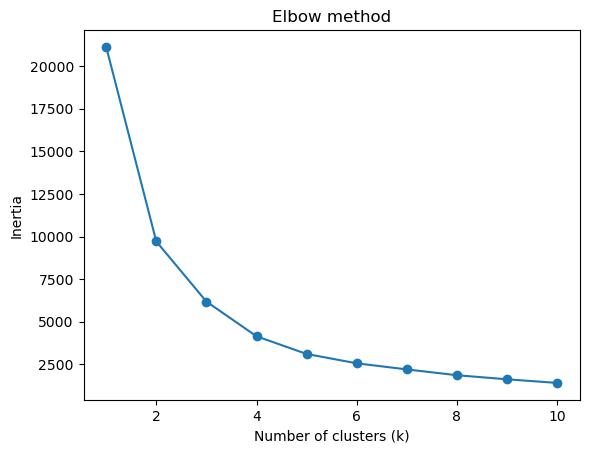

2 0.48
3 0.451
4 0.472
5 0.444
6 0.44
7 0.45
         customers  avg_tenure  avg_monthly  churn_rate
cluster                                                
0             2154       29.50        26.57        0.12
1             2200       58.56        89.70        0.15
2             2689       13.25        74.95        0.47


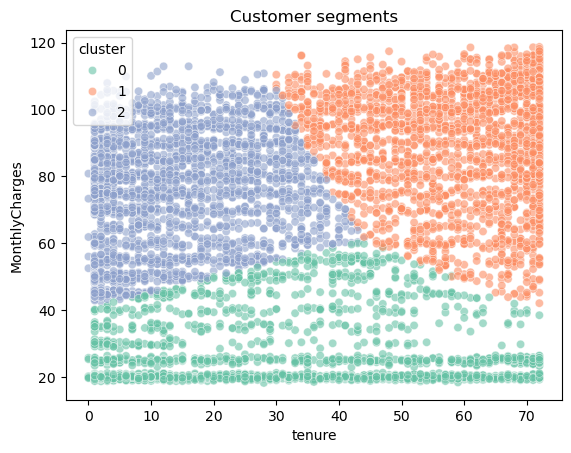

In [47]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import seaborn as sns

# Prepare and scale ---
features = ['tenure', 'MonthlyCharges', 'TotalCharges']
X_clu = StandardScaler().fit_transform(df[features])

# --- Task 2: Elbow method ---
inertias = []
ks = range(1, 11)
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_clu)
    inertias.append(km.inertia_)

plt.plot(ks, inertias, marker='o')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow method')
plt.show()

# Silhouette score ---
for k in range(2, 8):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_clu)
    print(k, round(silhouette_score(X_clu, km.labels_), 3))

# Fit k=3 and profile ---
km = KMeans(n_clusters=3, n_init=10, random_state=42).fit(X_clu)
df['cluster'] = km.labels_

profile = df.groupby('cluster').agg(
    customers=('tenure', 'size'),
    avg_tenure=('tenure', 'mean'),
    avg_monthly=('MonthlyCharges', 'mean'),
    churn_rate=('Churn', lambda s: (s == 'Yes').mean())
).round(2)
print(profile)

# Visualize ---
sns.scatterplot(data=df, x='tenure', y='MonthlyCharges', hue='cluster', palette='Set2', alpha=0.6)
plt.title('Customer segments')
plt.show()

## 13. PCA


[0.33247434 0.11976453 0.09036   ]
Components for 90%: 15
Components for 95%: 17


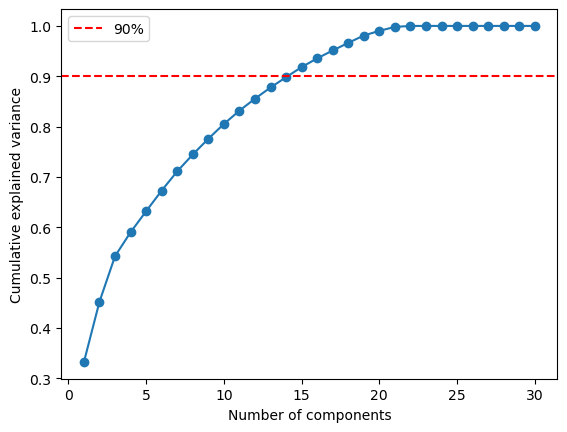

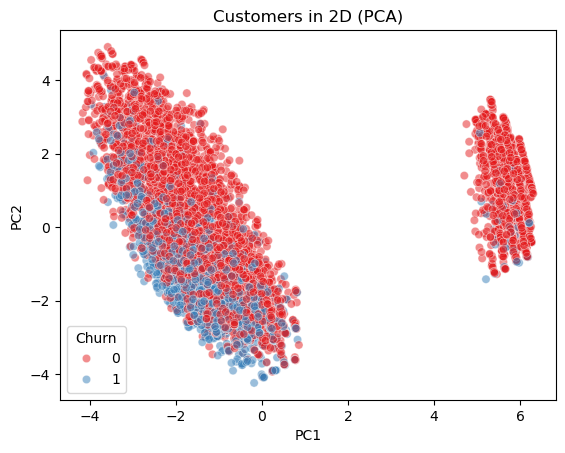

2 components: F1 = 0.578
5 components: F1 = 0.614
10 components: F1 = 0.624
15 components: F1 = 0.622
OnlineBackup_No internet service       0.301835
StreamingMovies_No internet service    0.301835
StreamingTV_No internet service        0.301835
TechSupport_No internet service        0.301835
InternetService_No                     0.301835
dtype: float64


In [49]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

# Scale and fit ---
X_scaled = StandardScaler().fit_transform(X_train)
pca = PCA().fit(X_scaled)

# Explained variance ---
print(pca.explained_variance_ratio_[:3])

cum_var = np.cumsum(pca.explained_variance_ratio_)
print('Components for 90%:', np.argmax(cum_var >= 0.90) + 1)
print('Components for 95%:', np.argmax(cum_var >= 0.95) + 1)

plt.plot(range(1, len(cum_var) + 1), cum_var, marker='o')
plt.axhline(0.90, color='red', linestyle='--', label='90%')
plt.xlabel('Number of components')
plt.ylabel('Cumulative explained variance')
plt.legend()
plt.show()

# Visualize in 2D ---
X_2d = PCA(n_components=2).fit_transform(X_scaled)
sns.scatterplot(x=X_2d[:, 0], y=X_2d[:, 1], hue=y_train, alpha=0.5, palette='Set1')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('Customers in 2D (PCA)')
plt.show()

# Does PCA help the model? ---
for n in [2, 5, 10, 15]:
    pipe = make_pipeline(StandardScaler(), PCA(n_components=n),
                         LogisticRegression(max_iter=1000, class_weight='balanced'))
    f1 = cross_val_score(pipe, X_train, y_train, cv=5, scoring='f1').mean()
    print(f'{n} components: F1 = {f1:.3f}')

# what makes up PC1? ---
pc1 = pd.Series(pca.components_[0], index=X_train.columns)
print(pc1.abs().sort_values(ascending=False).head(5))

## 14. Final Model Pipeline

In [23]:
## 14. Final model (pipeline)
import pandas as pd
import joblib
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression

# Start from the raw data (df now has extra columns from sections 9 and 12)
url = 'https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv'
raw = pd.read_csv(url)
raw['TotalCharges'] = pd.to_numeric(raw['TotalCharges'], errors='coerce')

X = raw.drop(columns=['customerID', 'Churn'])
y = (raw['Churn'] == 'Yes').astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

numeric = ['tenure', 'MonthlyCharges', 'TotalCharges']
categorical = [c for c in X.columns if c not in numeric]

preprocess = ColumnTransformer([
    ('num', Pipeline([
        ('impute', SimpleImputer(strategy='median')),
        ('scale', StandardScaler()),
    ]), numeric),
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical),
])

final_model = Pipeline([
    ('prep', preprocess),
    ('clf', LogisticRegression(max_iter=1000, class_weight='balanced')),
])

# Check it matches earlier results
f1 = cross_val_score(final_model, X_train, y_train, cv=5, scoring='f1')
print(f'CV F1: {f1.mean():.3f} ± {f1.std():.3f}')

# Train on all training data and save
final_model.fit(X_train, y_train)
joblib.dump(final_model, 'churn_model.joblib')

# Test: load it and predict on raw customers
loaded = joblib.load('churn_model.joblib')
probs = loaded.predict_proba(X_test.head(3))[:, 1]
print(probs.round(2))   # e.g. [0.09 0.89 0.2 ]

CV F1: 0.633 ± 0.026
[0.12 0.85 0.15]
